First 5 Rows of the Dataset:
   Feature1  Feature2  Target
0  0.803926 -0.291407       1
1  2.314433 -0.122238       1
2 -0.280392  0.450938       1
3  0.789446  0.384060       0
4  1.186657 -0.511438       1

Shape of the Dataset:
(300, 3)

Class Distribution:
Target
1    150
0    150
Name: count, dtype: int64


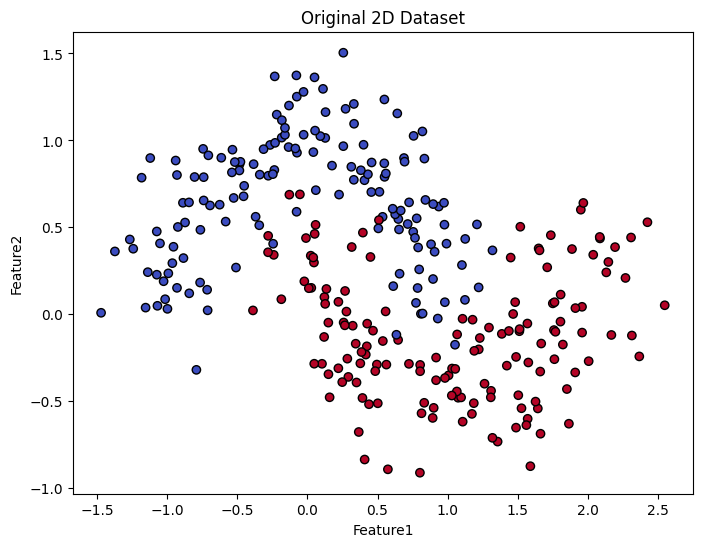


Training Data Shape: (210, 2)
Testing Data Shape: (90, 2)

Model Accuracy
Linear SVM Accuracy: 0.83
RBF SVM Accuracy: 0.92

Linear SVM Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.76      0.82        45
           1       0.79      0.91      0.85        45

    accuracy                           0.83        90
   macro avg       0.84      0.83      0.83        90
weighted avg       0.84      0.83      0.83        90


RBF SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.84      0.92        45
           1       0.87      1.00      0.93        45

    accuracy                           0.92        90
   macro avg       0.93      0.92      0.92        90
weighted avg       0.93      0.92      0.92        90


Number of Support Vectors:
Linear SVM: 66
RBF SVM: 53


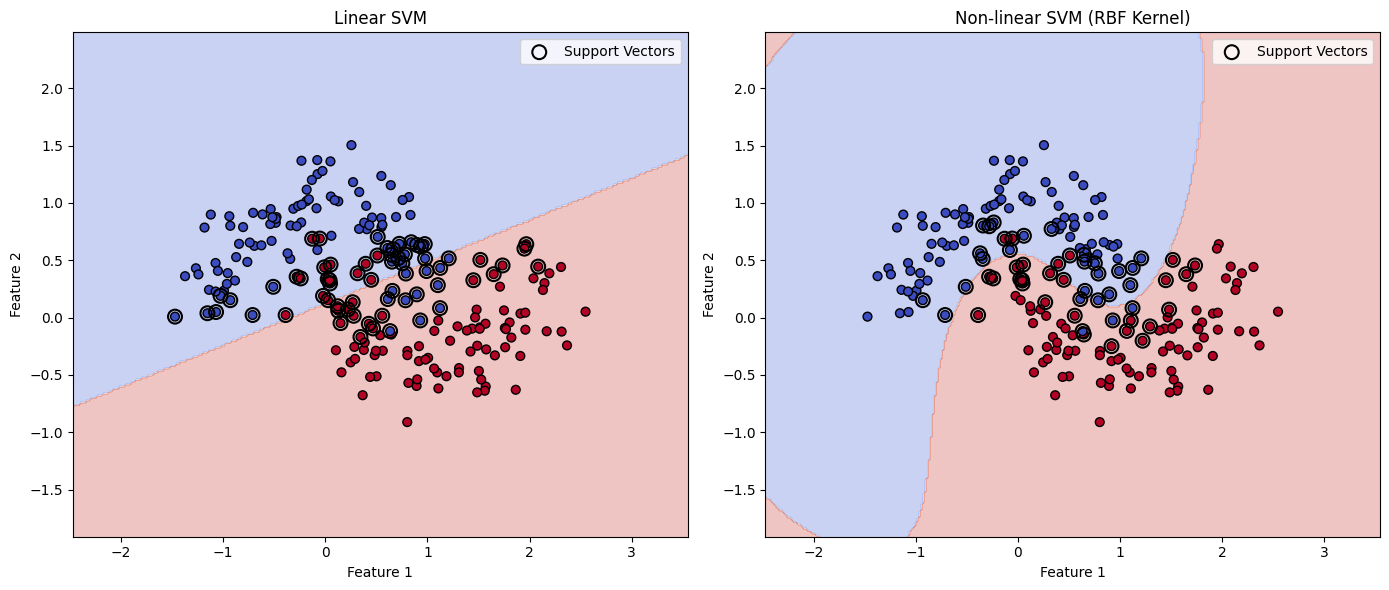

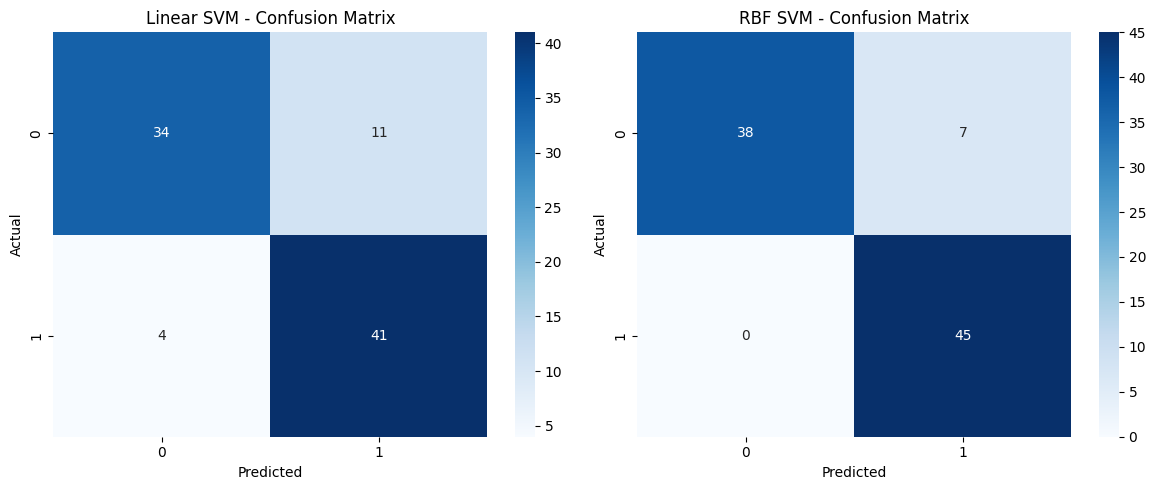


Conclusion:
RBF SVM performs better than Linear SVM for this non-linear dataset.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

df = pd.DataFrame(X, columns=["Feature1", "Feature2"])
df['Target'] = y

print("First 5 Rows of the Dataset:")
print(df.head())

print("\nShape of the Dataset:")
print(df.shape)

print("\nClass Distribution:")
print(df['Target'].value_counts())

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.xlabel('Feature1')
plt.ylabel('Feature2')
plt.title('Original 2D Dataset')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


linear_svm = SVC(kernel='linear', C=1.0)
rbf_svm = SVC(kernel='rbf', C=1.0, gamma='scale')


linear_svm.fit(X_train, y_train)
rbf_svm.fit(X_train, y_train)


linear_pred = linear_svm.predict(X_test)
rbf_pred = rbf_svm.predict(X_test)

linear_accuracy = accuracy_score(y_test, linear_pred)
rbf_accuracy = accuracy_score(y_test, rbf_pred)

print("\nModel Accuracy")
print("Linear SVM Accuracy:", round(linear_accuracy, 2))
print("RBF SVM Accuracy:", round(rbf_accuracy, 2))

print("\nLinear SVM Classification Report:")
print(classification_report(y_test, linear_pred))

print("\nRBF SVM Classification Report:")
print(classification_report(y_test, rbf_pred))

print("\nNumber of Support Vectors:")
print("Linear SVM:", len(linear_svm.support_vectors_))
print("RBF SVM:", len(rbf_svm.support_vectors_))

def plot_decision_boundary(model, X, y, ax, title):
    h = 0.02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=40)
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=100,
               facecolors='none', edgecolors='black', linewidths=1.5, label='Support Vectors')

    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_decision_boundary(linear_svm, X_train, y_train, axes[0], 'Linear SVM')
plot_decision_boundary(rbf_svm, X_train, y_train, axes[1], 'Non-linear SVM (RBF Kernel)')
plt.tight_layout()
plt.show()

linear_cm = confusion_matrix(y_test, linear_pred)
rbf_cm = confusion_matrix(y_test, rbf_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(linear_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Linear SVM - Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(rbf_cm, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('RBF SVM - Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

print("\nConclusion:")
if rbf_accuracy > linear_accuracy:
    print("RBF SVM performs better than Linear SVM for this non-linear dataset.")
elif linear_accuracy > rbf_accuracy:
    print("Linear SVM performs better than RBF SVM for this dataset.")
else:
    print("Both SVM models have the same accuracy.")

